In [29]:
import pandas as pd
df1 = pd.read_csv('nivelEducacionBajoBO(in).csv', delimiter =';')
df2 = pd.read_csv('nivelEducacionAltoBO(in).csv', delimiter = ';')
df1
df2

,Comunidades y Ciudades Autonomas,Porcentaje de la poblacion con un nivel alto (5-8)
0,Total nacional,37.7
1,Andalucía,32.7
2,Aragón,39.2
3,Asturias,40.2
4,Illes Balears,30.4
5,Canarias,31.6
6,Cantabria,45.4
7,Castilla y León,37.7
8,Castilla - La Mancha,30.4
9,Catalunya,40.4


      Comunidad Autonoma  Residuos (kg) por persona  Porcentaje_educacion_alta
0             Andaluci­a                  39.854210                       32.7
1                 Aragon                  51.153328                       39.2
2               Asturias                  42.942527                       40.2
3          Illes Balears                 113.897006                       30.4
4               Canarias                  53.052436                       31.6
5              Cantabria                  56.044405                       45.4
6   Castilla - La Mancha                  44.624668                       30.4
7        Castilla y Leon                  51.372915                       37.7
8                  Ceuta                  16.523199                       18.8
9   Comunitat Valenciana                  39.548021                       35.1
10           Extremadura                  39.629563                       31.8
11               Galicia                  55.389232 

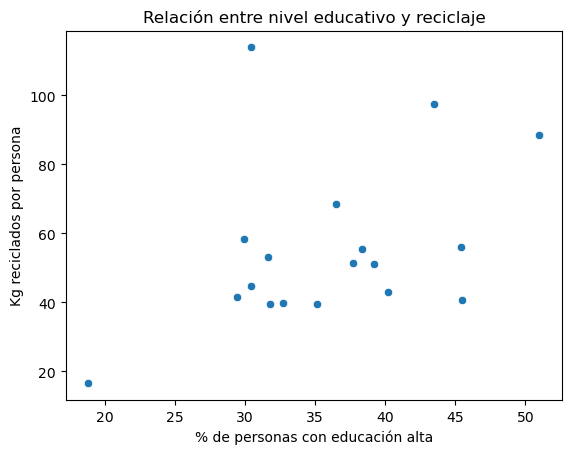

Coeficiente de correlación: 0.40297978158610354


In [83]:
### NIVEL EDUCATIVO ALTO ###


import pandas as pd
import unicodedata

# Función para quitar tildes y normalizar
def quitar_tildes(texto):
    texto = str(texto)
    texto = unicodedata.normalize('NFKD', texto).encode('ASCII', 'ignore').decode('utf-8')
    return texto.strip().lower()

# Leer educación (saltando fila 1)
df_educacion = pd.read_csv('nivelEducacionAltoBO(in).csv', delimiter=';', skiprows=1)
df_educacion.columns = ['Comunidad', 'Porcentaje_educacion_alta']

# Leer residuos
df_residuos = pd.read_csv('residuos_2023.csv', delimiter=',')

# Normalizar nombres de comunidad
df_educacion['Comunidad_normalizada'] = df_educacion['Comunidad'].apply(quitar_tildes)
df_residuos['Comunidad_normalizada'] = df_residuos['Comunidad Autonoma'].apply(quitar_tildes)

# Merge
df_merged = pd.merge(
    df_residuos,
    df_educacion[['Comunidad_normalizada', 'Porcentaje_educacion_alta']],
    on='Comunidad_normalizada',
    how='inner'
)

# Ver resultado
print(df_merged[['Comunidad Autonoma', 'Residuos (kg) por persona', 'Porcentaje_educacion_alta']])

import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(data=df_merged, x="Porcentaje_educacion_alta", y="Residuos (kg) por persona")
plt.title("Relación entre nivel educativo y reciclaje")
plt.xlabel("% de personas con educación alta")
plt.ylabel("Kg reciclados por persona")
plt.show()


#podemos relacionarlos porque ambos valores son indicadores a nivel de comunidad y están normalizados por población
correlacion = df_merged["Porcentaje_educacion_alta"].corr(df_merged["Residuos (kg) por persona"])
print(f"Coeficiente de correlación: {correlacion}")


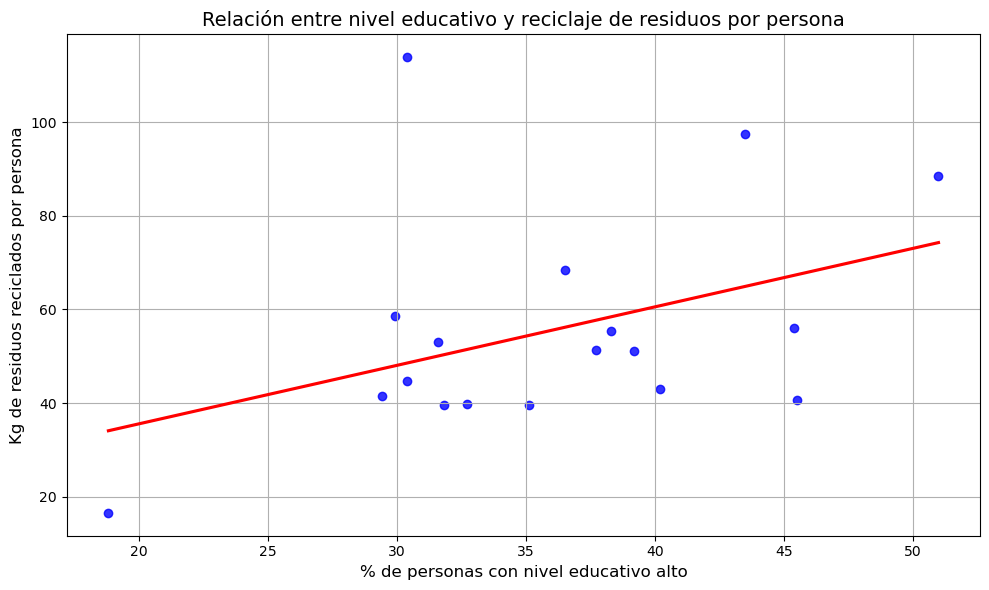

In [85]:
import matplotlib.pyplot as plt
import seaborn as sns

# Tamaño del gráfico
plt.figure(figsize=(10, 6))

# Gráfico de dispersión
sns.regplot(
    data=df_merged,
    x='Porcentaje_educacion_alta',
    y='Residuos (kg) por persona',
    ci=None,
    scatter_kws={"color": "blue"},
    line_kws={"color": "red"}
)

# Títulos
plt.title('Relación entre nivel educativo y reciclaje de residuos por persona', fontsize=14)
plt.xlabel('% de personas con nivel educativo alto', fontsize=12)
plt.ylabel('Kg de residuos reciclados por persona', fontsize=12)

plt.grid(True)
plt.tight_layout()
plt.show()


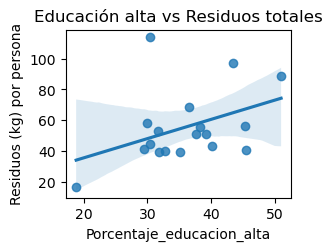

In [87]:
plt.subplot(2, 2, 4)
sns.regplot(x='Porcentaje_educacion_alta', y='Residuos (kg) por persona', data=df_merged)
plt.title('Educación alta vs Residuos totales')

plt.show()

      Comunidad Autonoma  Residuos (kg) por persona  Porcentaje_educacion_baja
0             Andaluci­a                  39.854210                       42.9
1                 Aragon                  51.153328                       34.6
2               Asturias                  42.942527                       31.7
3          Illes Balears                 113.897006                       39.3
4               Canarias                  53.052436                       38.6
5              Cantabria                  56.044405                       27.6
6   Castilla - La Mancha                  44.624668                       45.0
7        Castilla y Leon                  51.372915                       35.3
8                  Ceuta                  16.523199                       60.1
9   Comunitat Valenciana                  39.548021                       40.5
10           Extremadura                  39.629563                       45.1
11               Galicia                  55.389232 

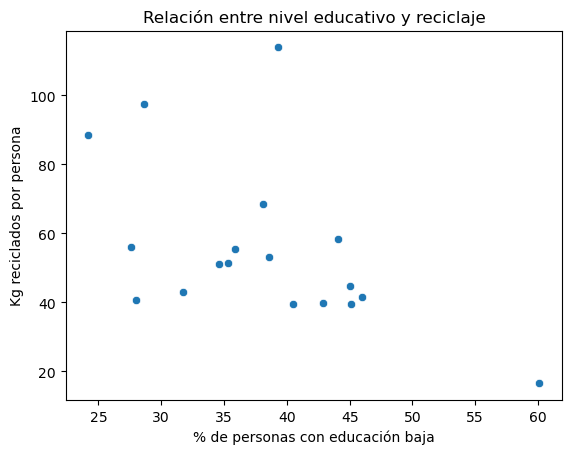

Coeficiente de correlación: -0.515696656609079


In [67]:
### NIVEL EDUCATICO BAJO ###
import pandas as pd
import unicodedata

# Función para quitar tildes y normalizar
def quitar_tildes(texto):
    texto = str(texto)
    texto = unicodedata.normalize('NFKD', texto).encode('ASCII', 'ignore').decode('utf-8')
    return texto.strip().lower()

# Leer educación (saltando fila 1)
df_educacionB = pd.read_csv('nivelEducacionBajoBO(in).csv', delimiter=';', skiprows=1)
df_educacionB.columns = ['Comunidad', 'Porcentaje_educacion_baja']

# Leer residuos
df_residuos = pd.read_csv('residuos_2023.csv', delimiter=',')

# Normalizar nombres de comunidad
df_educacionB['Comunidad_normalizada'] = df_educacionB['Comunidad'].apply(quitar_tildes)
df_residuos['Comunidad_normalizada'] = df_residuos['Comunidad Autonoma'].apply(quitar_tildes)

# Merge
df_merged2 = pd.merge(
    df_residuos,
    df_educacionB[['Comunidad_normalizada', 'Porcentaje_educacion_baja']],
    on='Comunidad_normalizada',
    how='inner'
)

# Ver resultado
print(df_merged2[['Comunidad Autonoma', 'Residuos (kg) por persona', 'Porcentaje_educacion_baja']])

import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(data=df_merged2, x="Porcentaje_educacion_baja", y="Residuos (kg) por persona")
plt.title("Relación entre nivel educativo y reciclaje")
plt.xlabel("% de personas con educación baja")
plt.ylabel("Kg reciclados por persona")
plt.show()


#podemos relacionarlos porque ambos valores son indicadores a nivel de comunidad y están normalizados por población
correlacion2 = df_merged2["Porcentaje_educacion_baja"].corr(df_merged2["Residuos (kg) por persona"])
print(f"Coeficiente de correlación: {correlacion2}")


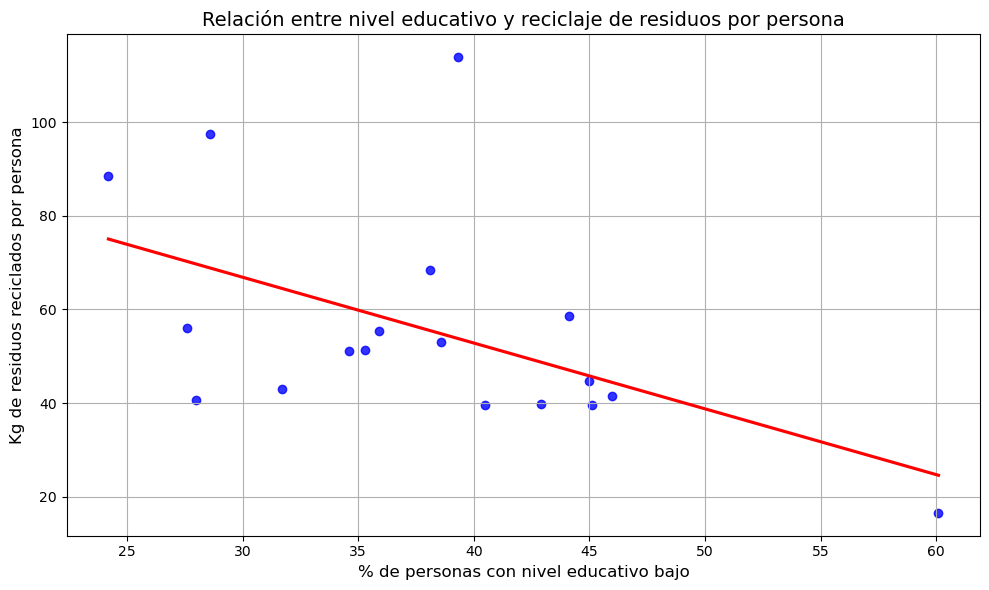

In [69]:
import matplotlib.pyplot as plt
import seaborn as sns

# Tamaño del gráfico
plt.figure(figsize=(10, 6))

# Gráfico de dispersión
sns.regplot(
    data=df_merged2,
    x='Porcentaje_educacion_baja',
    y='Residuos (kg) por persona',
    ci=None,
    scatter_kws={"color": "blue"},
    line_kws={"color": "red"}
)

# Títulos
plt.title('Relación entre nivel educativo y reciclaje de residuos por persona', fontsize=14)
plt.xlabel('% de personas con nivel educativo bajo', fontsize=12)
plt.ylabel('Kg de residuos reciclados por persona', fontsize=12)

plt.grid(True)
plt.tight_layout()
plt.show()

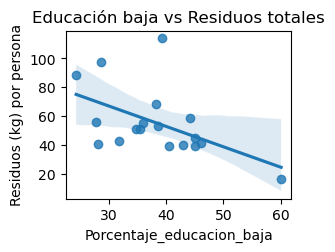

In [79]:
plt.subplot(2, 2, 4)
sns.regplot(x='Porcentaje_educacion_baja', y='Residuos (kg) por persona', data=df_merged2)
plt.title('Educación baja vs Residuos totales')

plt.show()